# Módulo 4 — Autocovariância, ACF e PACF

## Seção 2 — Estimação amostral da autocovariância e da função de autocorrelação (ACF)

**Estado:** versão para revisão científica e pedagógica.  
**Pré-requisitos:** Módulo 1 (esperança, variância, estacionariedade fraca), Módulo 3 (diferenciação), Módulo 4, Seção 1 (autocovariância teórica, AR(1) e MA(1)).  
**Nota de implementação:** Python 3 com NumPy, Matplotlib e Statsmodels. Dados dos exemplos computacionais são **simulados**, não observações reais.

**Base acadêmica efetivamente consultada:** Morettin e Toloi, *Análise de Séries Temporais — Modelos lineares univariados*, vol. 1, 3ª ed., §2.5, p. 34, eq. (2.17), para a autocovariância amostral com divisor $N$. O mapeamento das aulas do projeto lista o bloco de oito aulas de autocorrelação amostral e a aula de ACF/CCF/diferenciação. **Complementação didática original:** cálculo manual, viés sob média conhecida, variabilidade amostral, comparação entre convenções de divisor, código e exercícios. A discussão completa dos padrões de ARMA fica para capítulo posterior.

### Objetivos de aprendizagem

Ao final, você deverá (i) diferenciar função teórica de estimativa amostral, (ii) deduzir $\\widehat{\\gamma}(h)$ e $\\widehat{\\rho}(h)$, (iii) calcular uma ACF manualmente, (iv) entender denominadores alternativos e as hipóteses de uma referência aproximada de incerteza, (v) reproduzir as contas com NumPy e Statsmodels e (vi) interpretar limites de identificação com uma trajetória finita.

### 1. Problema: como estimar dependência temporal observando uma única trajetória?

Na Seção 1 definimos a autocovariância teórica do processo fracamente estacionário:

$$
\gamma(h)=E[(Z_t-\mu)(Z_{t+h}-\mu)],
$$

com média constante $\mu$ e variância $\gamma(0)>0$. A função de autocorrelação **teórica** é

$$
\rho(h)=\frac{\gamma(h)}{\gamma(0)},\qquad \rho(0)=1.
$$

Essas expressões usam esperança sobre a distribuição do processo. Na prática, recebemos uma única sequência $z_1,\ldots,z_N$. É necessário substituir expectativas desconhecidas por médias calculadas dos dados. **Um valor observado de autocorrelação não é uma propriedade exata do processo; é uma estatística aleatória.**

### 2. Estimador de autocovariância com divisor $N$

A média amostral é

$$
\overline z=\frac1N\sum_{t=1}^{N}z_t.
$$

Para uma defasagem inteira $h$, com $0\le h<N$, os pares disponíveis são

$$
(z_1,z_{1+h}),\;(z_2,z_{2+h}),\;\ldots,\;(z_{N-h},z_N).
$$

Existem $N-h$ produtos. Adotando a convenção de Morettin e Toloi, eq. (2.17), a **autocovariância amostral** é

$$
\boxed{\widehat\gamma_N(h)=\frac1N\sum_{t=1}^{N-h}(z_t-\overline z)(z_{t+h}-\overline z).}
$$

Definimos $\widehat\gamma_N(-h)=\widehat\gamma_N(h)$ para defasagens negativas. Para $h=0$,

$$
\widehat\gamma_N(0)=\frac1N\sum_{t=1}^{N}(z_t-\overline z)^2.
$$

Esta é a variância amostral com divisor $N$, não a variância corrigida com $N-1$. Por isso as convenções precisam ser documentadas antes de comparar saídas de diferentes programas.

**Por que o divisor é $N$ se há apenas $N-h$ pares?** O divisor comum produz uma sequência de autocovariâncias amostrais coerente com a semidefinição positiva (quando a série é estendida por zero fora da amostra após centralização). Já uma correção por $N-h$ pode reduzir um tipo de viés, mas não preserva necessariamente essa propriedade para todos os valores estimados em conjunto.

### 3. Da autocovariância à ACF amostral

Se $\widehat\gamma_N(0)>0$, definimos

$$
\boxed{\widehat\rho_N(h)=\frac{\widehat\gamma_N(h)}{\widehat\gamma_N(0)},\qquad h=0,1,\ldots,N-1.}
$$

Assim $\widehat\rho_N(0)=1$ e $|\widehat\rho_N(h)|\le1$ na convenção adotada. A divisão cancela uma mudança de escala multiplicativa da série. Se todos os valores forem iguais, a variância estimada será zero e a ACF não estará definida.

**Interpretação:** $\widehat\rho_N(1)$ é a associação linear estimada entre valores consecutivos; $\widehat\rho_N(12)$ compara observações separadas por 12 passos. Esses valores **não demonstram independência**, causalidade ou estacionariedade. Sazonalidade e tendência não tratadas podem distorcer sua interpretação.

### 4. Exemplo manual resolvido: cinco observações

Considere a trajetória finita

$$
(z_1,z_2,z_3,z_4,z_5)=(2,4,3,5,6).
$$

**Passo 1 — média:**

$$
\overline z=\frac{2+4+3+5+6}{5}=4.
$$

**Passo 2 — desvios:**

$$
(d_1,d_2,d_3,d_4,d_5)=(-2,0,-1,1,2).
$$

**Passo 3 — defasagem zero:**

$$
\widehat\gamma_N(0)=\frac{(-2)^2+0^2+(-1)^2+1^2+2^2}{5}=\frac{10}{5}=2.
$$

**Passo 4 — defasagem um:**

$$
\begin{aligned}
\widehat\gamma_N(1)
&=\frac{d_1d_2+d_2d_3+d_3d_4+d_4d_5}{5}\\
&=\frac{0+0-1+2}{5}=0{,}2.
\end{aligned}
$$

Logo,

$$
\widehat\rho_N(1)=\frac{0{,}2}{2}=0{,}1.
$$

**Passo 5 — defasagem dois:**

$$
\widehat\gamma_N(2)=\frac{d_1d_3+d_2d_4+d_3d_5}{5}
=\frac{2+0-2}{5}=0,
$$

portanto $\widehat\rho_N(2)=0$. Este é **um resultado amostral**: não prova $\rho(2)=0$ na população.

### 5. Dois denominadores e seus limites

Outra convenção é

$$
\widetilde\gamma_N(h)=\frac{1}{N-h}\sum_{t=1}^{N-h}(z_t-\overline z)(z_{t+h}-\overline z).
$$

No exemplo, para $h=1$, temos $\widetilde\gamma_N(1)=1/4=0{,}25$, enquanto $\widehat\gamma_N(1)=0{,}20$. A diferença entre estimadores aumenta nas defasagens maiores, pois há menos pares. **Não chame automaticamente $\widetilde\gamma_N$ de “não viesado” quando $\mu$ foi substituída por $\overline z$.** Mesmo sob estacionariedade, a centralização por média estimada introduz efeitos de viés dependentes da estrutura de dependência. Quando a média populacional $\mu$ é conhecida, a estimativa com divisor $N-h$ é não viesada para $\gamma(h)$ sob estacionariedade de segunda ordem.

**Limitações práticas:** usar defasagens muito próximas de $N$ produz estatísticas instáveis; uma boa prática é escolher uma faixa moderada em função do fenômeno e do tamanho amostral, declarando a escolha.

### 6. Python — implementação conceitual, biblioteca e gráfico

Primeiro reproduzimos o cálculo manual, deixando cada operação visível:

In [ ]:
import numpy as np

z = np.array([2., 4., 3., 5., 6.])
n = len(z)
desvios = z - np.mean(z)

def acov_com_divisor_n(x, max_lag):
    x = np.asarray(x, dtype=float)
    n = len(x)
    if not 0 <= max_lag < n:
        raise ValueError("max_lag deve estar entre 0 e n-1")
    d = x - np.mean(x)
    valores = []
    for h in range(max_lag + 1):
        produtos = d[:n-h] * d[h:]
        valores.append(np.sum(produtos) / n)
    return np.array(valores)

g = acov_com_divisor_n(z, max_lag=2)
r = g / g[0]
print("autocovariâncias:", g)
print("autocorrelações:", r)
# Esperado: [2. , 0.2, 0. ] e [1. , 0.1, 0. ]


Em `d[:n-h]` selecionamos a primeira parte de cada par; em `d[h:]`, a segunda. O produto elemento a elemento é somado por `np.sum`. O vetor devolvido inclui a defasagem zero.

**Validação usando Statsmodels:** a função `acf` estima autocorrelações até `nlags`; `adjusted=False` corresponde ao denominador comum $N$ da autocovariância. Definimos `fft=False` para explicitar que não é necessária aceleração por FFT no pequeno exemplo.

In [ ]:
from statsmodels.tsa.stattools import acf
r_biblioteca = acf(z, nlags=2, adjusted=False, fft=False)
print(r_biblioteca)
assert np.allclose(r, r_biblioteca)


Agora analisamos um processo AR(1) **simulado**:

$$
Z_t=0{,}65Z_{t-1}+\varepsilon_t,\qquad
\varepsilon_t\ \text{i.i.d. }N(0,1).
$$

Uma solução estacionária causal tem ACF teórica $\rho(h)=0{,}65^{|h|}$. Para reduzir o efeito da condição inicial, descartamos as primeiras 300 observações do algoritmo recursivo:

In [ ]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261117)
n, descarte, phi = 800, 300, 0.65
e = rng.normal(0, 1, n + descarte)
x = np.zeros(n + descarte)
for t in range(1, len(x)):
    x[t] = phi * x[t - 1] + e[t]
x = x[descarte:]

max_lag = 25
g = acov_com_divisor_n(x, max_lag)
r_estimado = g / g[0]
h = np.arange(max_lag + 1)
r_teorico = phi ** h

plt.figure(figsize=(9, 4))
plt.axhline(0, color="gray", linewidth=0.8)
plt.vlines(h, 0, r_estimado, label="ACF amostral")
plt.plot(h, r_teorico, "o--", label="ACF teórica")
plt.xlabel("Defasagem h")
plt.ylabel("Autocorrelação")
plt.title("AR(1): teoria versus amostra simulada")
plt.legend()
plt.show()

assert np.allclose(
    r_estimado,
    acf(x, nlags=max_lag, adjusted=False, fft=False)
)


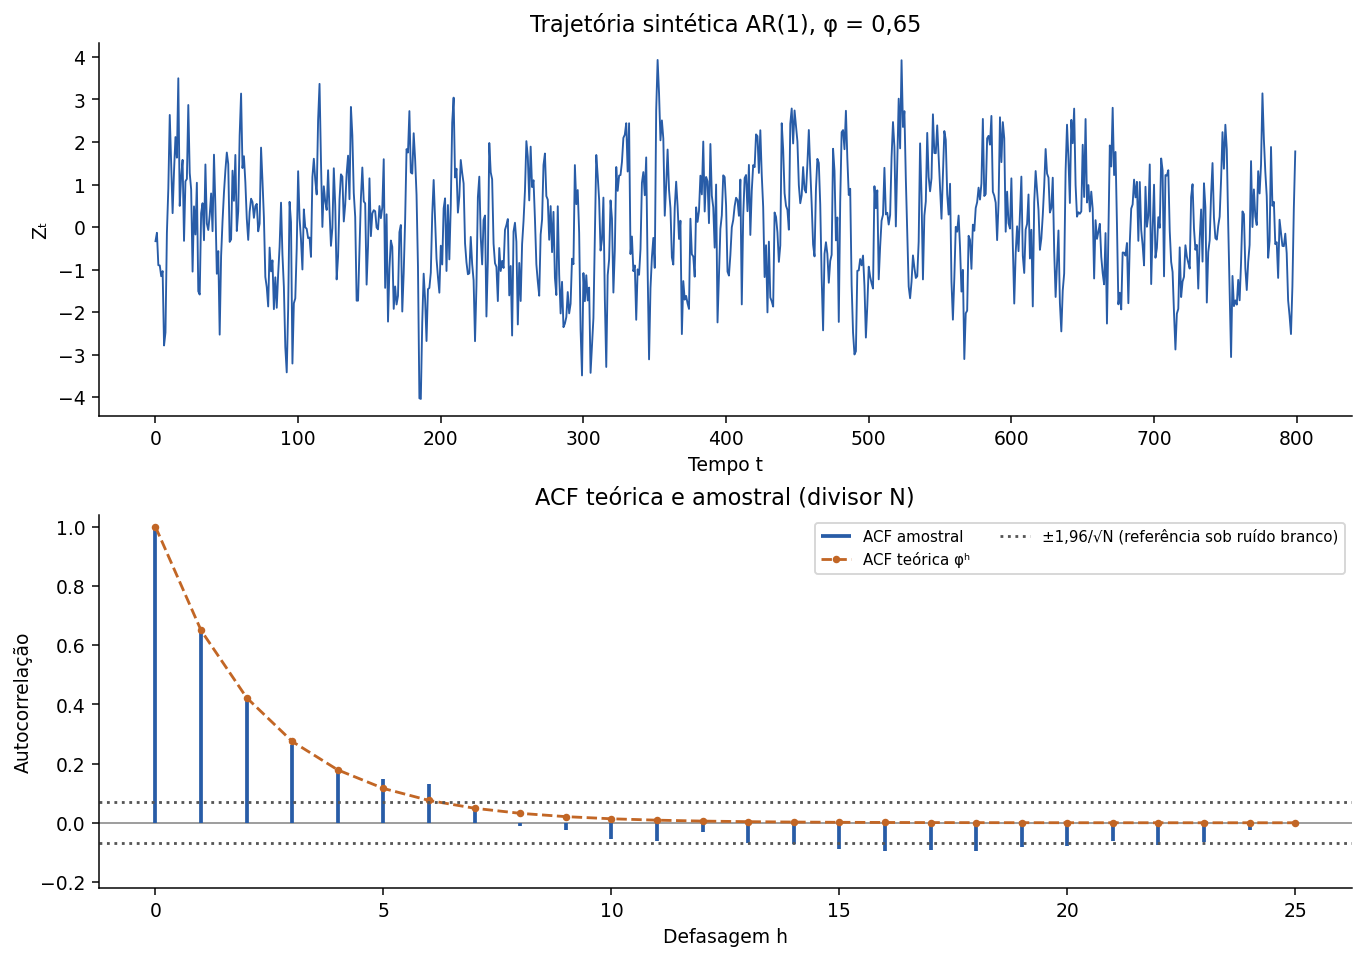

*Figura 1 — Trajetória simulada e comparação entre ACF teórica e amostral de AR(1). A diferença entre as curvas decorre da amostragem finita; a curva teórica foi deduzida do modelo, não estimada.*

### 7. Leitura de gráficos e incerteza: uma ressalva indispensável

Em gráficos de ACF, é frequente encontrar linhas em torno de

$$
\pm\frac{1{,}96}{\sqrt N}.
$$

Essa aproximação é uma referência assintótica de cerca de 95% **para autocorrelações amostrais de ruído branco em defasagens não nulas, sob hipóteses apropriadas**. **Não é uma banda universal para todo processo**, não garante cobertura simultânea de muitas defasagens e não implica que picos isolados constituam prova definitiva de dependência. No gráfico acima, a referência é exibida apenas para ilustrar esse cuidado: a ACF do AR(1) tem autocorrelações teóricas não nulas.

O tamanho amostral $N$, a escolha de defasagens, valores ausentes e transformações prévias precisam ser registrados numa análise científica. Um gráfico de ACF de um passeio aleatório sem diferenciação não deve ser interpretado da mesma maneira que o de um processo estacionário.

### 8. Exercícios com orientação de resolução

1. **Cálculo manual.** Para $z=(1,2,4,3)$, calcule $\overline z$, $\widehat\gamma_N(0)$, $\widehat\gamma_N(1)$ e $\widehat\rho_N(1)$. *Orientação:* escreva os desvios e use somente três produtos para $h=1$.
2. **Demonstração.** Supondo média populacional $\mu$ conhecida e estacionariedade fraca, demonstre que $E[(N-h)^{-1}\sum_{t=1}^{N-h}(Z_t-\mu)(Z_{t+h}-\mu)]=\gamma(h)$.
3. **Programação guiada.** Altere o exemplo AR(1) para $\phi=-0{,}6$. Antes de executar, esboce o sinal esperado da ACF teórica nas defasagens 1–5.
4. **Interpretação.** Explique por que $\widehat\rho(2)=0$ em uma amostra pequena não demonstra independência entre $Z_t$ e $Z_{t+2}$.
5. **Investigação.** Compare `adjusted=True` e `adjusted=False` em `statsmodels.tsa.stattools.acf`, verificando qual denominador cada opção implementa para a autocovariância que fundamenta a ACF.

**Resposta selecionada, exercício 2:** cada produto tem esperança $\gamma(h)$; pela linearidade da esperança, a média de $N-h$ produtos conserva essa esperança. A demonstração deixa de se aplicar literalmente quando a média desconhecida é substituída por $\overline Z$.

### Síntese e referências

A ACF estimada resume dependência linear em uma realização finita, mas não substitui a definição probabilística de autocovariância. A convenção de divisor precisa ser explícita e os intervalos aproximados de interpretação exigem hipóteses.

- MORETTIN, P. A.; TOLOI, C. M. C. *Análise de Séries Temporais: Modelos lineares univariados*, v. 1, 3ª ed., §2.5, p. 34, eq. (2.17). Consulta visual ao PDF local, p. 53 do arquivo.
- `mapeamento-conteudos-series-temporais.md`, bloco D, registros 44–51, e aula 4 (ACF/CCF/diferenciação). Utilizado para alinhamento pedagógico, não como fonte de demonstrações.
- Cálculos numéricos, explicações sobre divisores, scripts e figura: complementações didáticas elaboradas para este capítulo.